In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats

warnings.filterwarnings('ignore')


In [3]:
# creating database connection
conn = sqlite3.connect('inventoryy.db')

# fetching vendor summary data
df = pd.read_sql_query("SELECT * FROM vendor_sales_summary", conn)
df.head()


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StokTurnover,SalesPurchaseRatio
0,1128.0,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,131655.0,3458576.85,24010.0,864119.90,152741.56,44114.93,68601.68,-2594456.95,-300.242704,0.182371,0.249848
1,4425.0,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,144999.0,3362526.81,21827.0,659924.73,123377.51,40104.07,144929.24,-2702602.08,-409.531869,0.150532,0.196259
2,17035.0,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,170712.0,3113786.88,28862.0,729783.38,109452.79,53030.17,123780.22,-2384003.50,-326.672759,0.169068,0.234372
3,3960.0,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,170717.0,2760493.89,47051.0,1046263.49,100839.72,86452.65,257032.07,-1714230.40,-163.843087,0.275608,0.379013
4,3960.0,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,124085.0,2716220.65,26684.0,813085.16,121120.43,49028.63,257032.07,-1903135.49,-234.063489,0.215046,0.299344


Exploratory Data Analysis
Previously, we examined the various tables in the database to identify key variables, understand their relationships, and determine which ones should be included in the final analysis.

In this phase of EDA, we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identify anomalies, and ensure data quality before proceeding with further analysis.

In [4]:
#summary stastistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10505.0,1.057321e+04,18622.096781,2.00,3924.00,7153.000000,9552.000000,2.013590e+05
Brand,10505.0,1.801111e+04,12682.460292,58.00,5776.00,18664.000000,25429.000000,9.063100e+04
PurchasePrice,10505.0,2.380378e+01,107.404597,0.36,6.84,10.380000,19.220000,5.681810e+03
ActualPrice,10505.0,3.485345e+01,146.084704,0.49,10.99,15.990000,27.990000,7.499990e+03
Volume,10505.0,8.469257e+02,642.611526,50.00,750.00,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10505.0,2.830779e+03,9938.081008,1.00,34.00,251.000000,1786.000000,3.023990e+05
TotalPurchaseDollars,10505.0,2.711692e+04,111083.922293,0.71,415.68,3433.210000,18986.160000,3.458577e+06
TotalSalesQuantity,10505.0,5.690166e+02,2126.659180,0.00,0.00,36.000000,325.000000,7.017300e+04
TotalSalesDollars,10505.0,7.621551e+03,29597.900037,0.00,0.00,703.560000,5132.330000,1.046263e+06
TotalSalesPrice,10505.0,3.707668e+03,9457.119624,0.00,0.00,349.930000,2974.320000,1.527416e+05


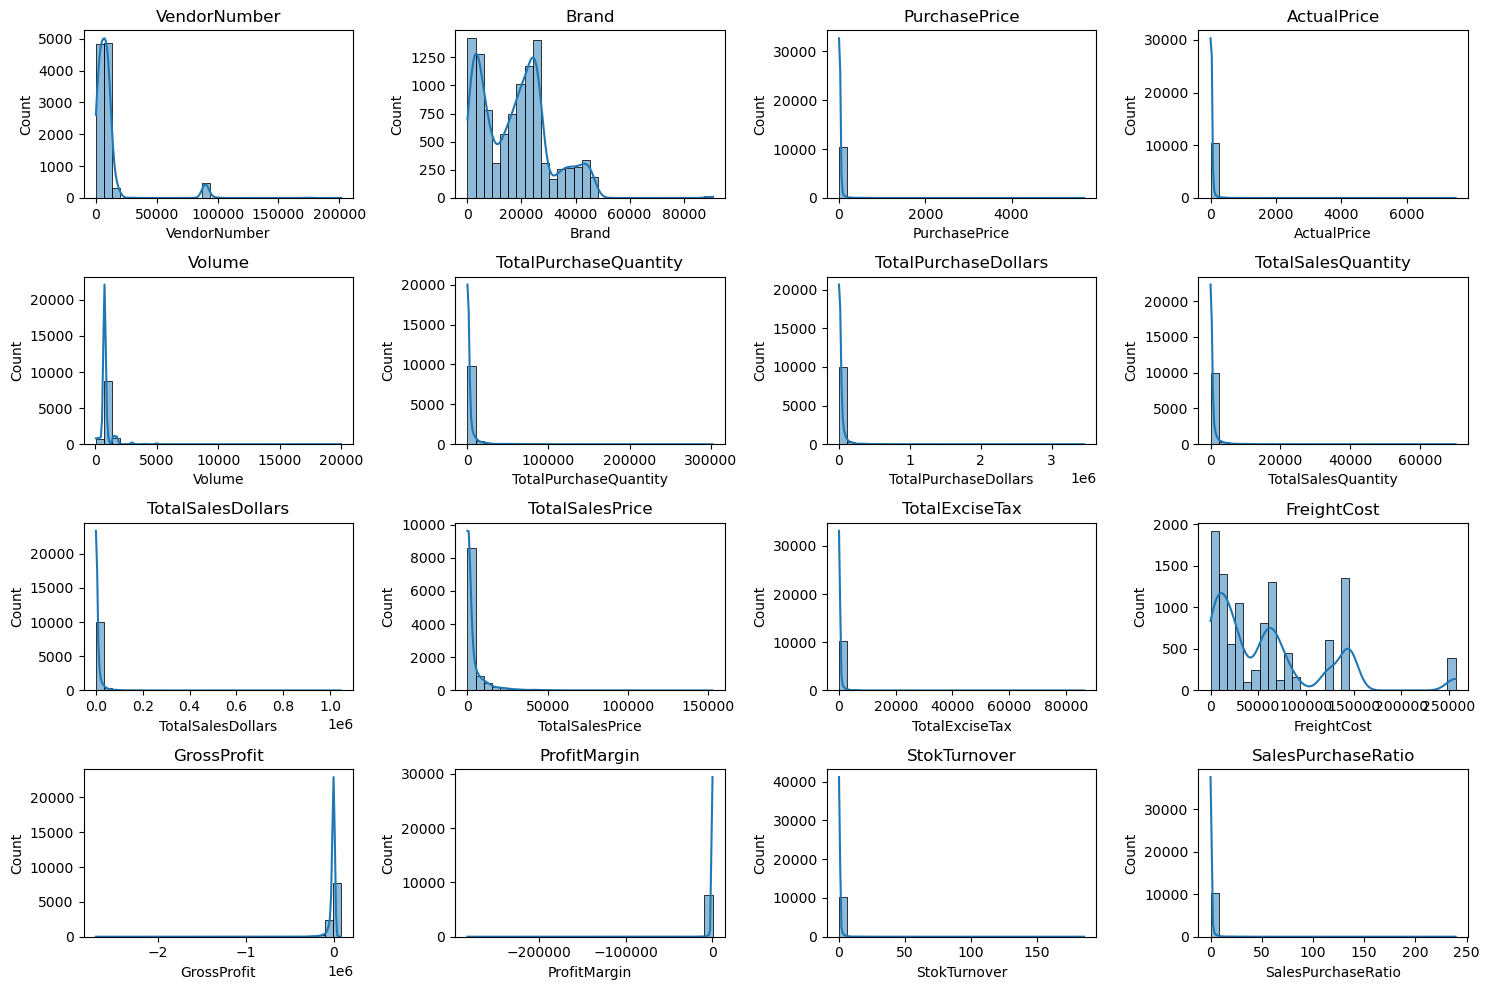

In [5]:
#Distribution Plot For Numerical Columns
numerical_cols=df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15,10))
for i , col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1) #Adjust grid layout as needed
    sns.histplot(df[col],kde=True,bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

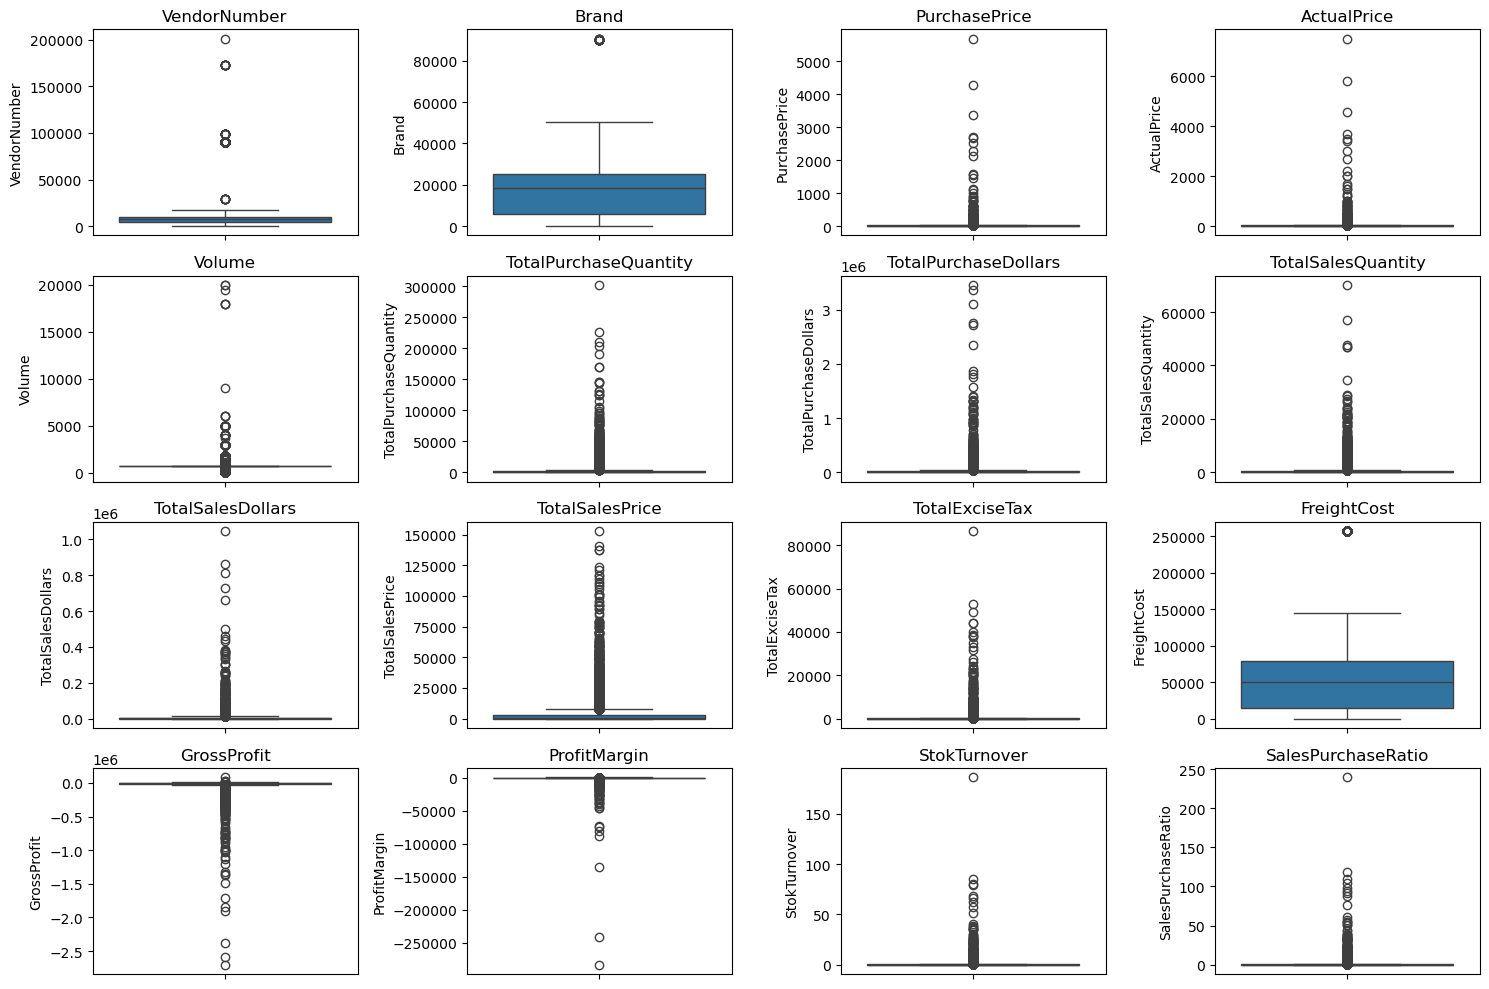

In [6]:
#outlier Detection with Boxplot
plt.figure(figsize=(15,10))
for i , col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1) #Adjust grid layout as needed
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [7]:
# let's filter the data by removing inconsistencies
df = pd.read_sql_query("""SELECT *
FROM vendor_sales_summary
WHERE GrossProfit > 0
AND ProfitMargin > 0
AND TotalSalesQuantity > 0""", conn)


In [8]:
df

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StokTurnover,SalesPurchaseRatio
0,12546.0,JIM BEAM BRANDS COMPANY,1476,Jim Beam Traveler,16.05,21.99,1750.0,11569.0,185682.45,11727.0,266138.73,74006.34,21545.79,123880.97,80456.28,30.230955,1.013657,1.433300
1,3960.0,DIAGEO NORTH AMERICA INC,2492,Crown Royal Hand Slct Barrel,41.66,54.99,750.0,755.0,31453.30,635.0,34918.65,4949.10,500.12,257032.07,3465.35,9.924066,0.841060,1.110174
2,8112.0,MOET HENNESSY USA INC,1023,Hennessy VSOP Cognac + 50mL,35.93,45.99,750.0,756.0,27163.08,694.0,36607.06,8093.46,546.61,48347.26,9443.98,25.798248,0.917989,1.347677
3,9165.0,ULTRA BEVERAGE COMPANY LLP,15035,Morellino d Scansano Rsv,7.33,10.99,750.0,3592.0,26329.36,2516.0,27650.84,9901.99,281.47,68054.70,1321.48,4.779168,0.700445,1.050190
4,10754.0,PERFECTA WINES,25197,Ch La Rousseliere St Estephe,99.33,149.99,750.0,250.0,24832.50,199.0,29848.01,1349.91,22.35,28720.52,5015.51,16.803499,0.796000,1.201974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1311,3960.0,DIAGEO NORTH AMERICA INC,2626,Crown Royal Apple,1.42,1.99,50.0,2.0,2.84,12.0,23.88,1.99,0.63,257032.07,21.04,88.107203,6.000000,8.408451
1312,9815.0,WINE GROUP INC,8527,Concannon Glen Ellen Wh Zin,1.32,4.99,750.0,2.0,2.64,3.0,5.97,5.97,0.33,27100.41,3.33,55.778894,1.500000,2.261364
1313,8004.0,SAZERAC CO INC,5683,Dr McGillicuddy's Apple Pie,0.39,0.49,50.0,6.0,2.34,128.0,62.72,0.98,6.72,50293.62,60.38,96.269133,21.333333,26.803419
1314,3960.0,DIAGEO NORTH AMERICA INC,6127,The Club Strawbry Margarita,1.47,1.99,200.0,1.0,1.47,6.0,11.94,7.96,1.26,257032.07,10.47,87.688442,6.000000,8.122449


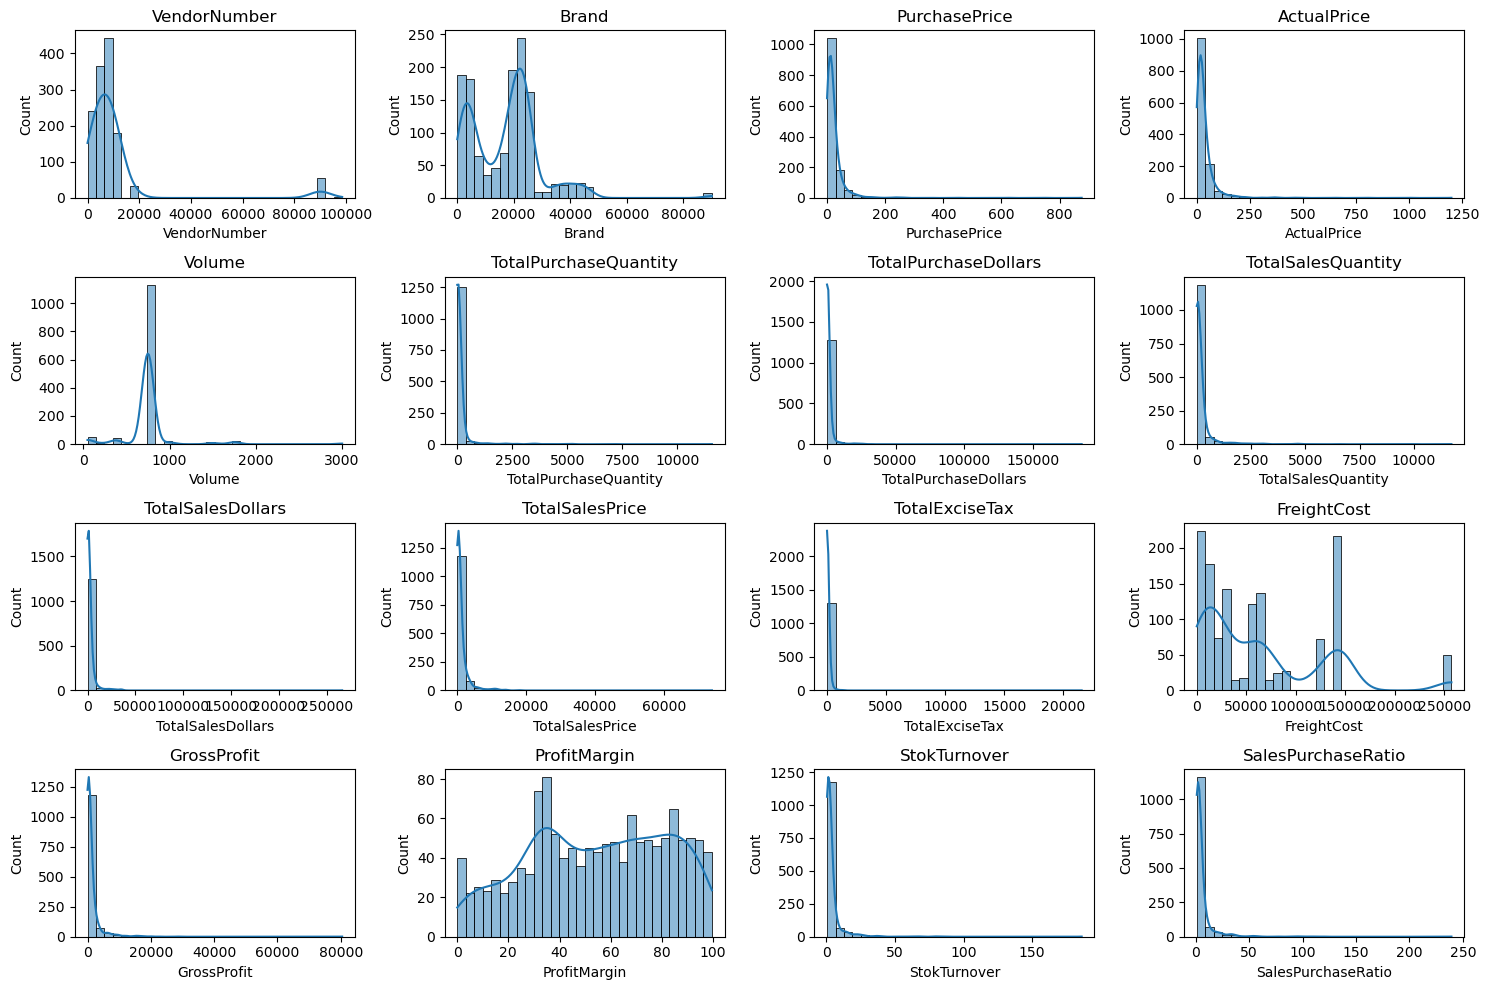

In [9]:
#Distribution Plot For Numerical Columns
numerical_cols=df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15,10))
for i , col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1) #Adjust grid layout as needed
    sns.histplot(df[col],kde=True,bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

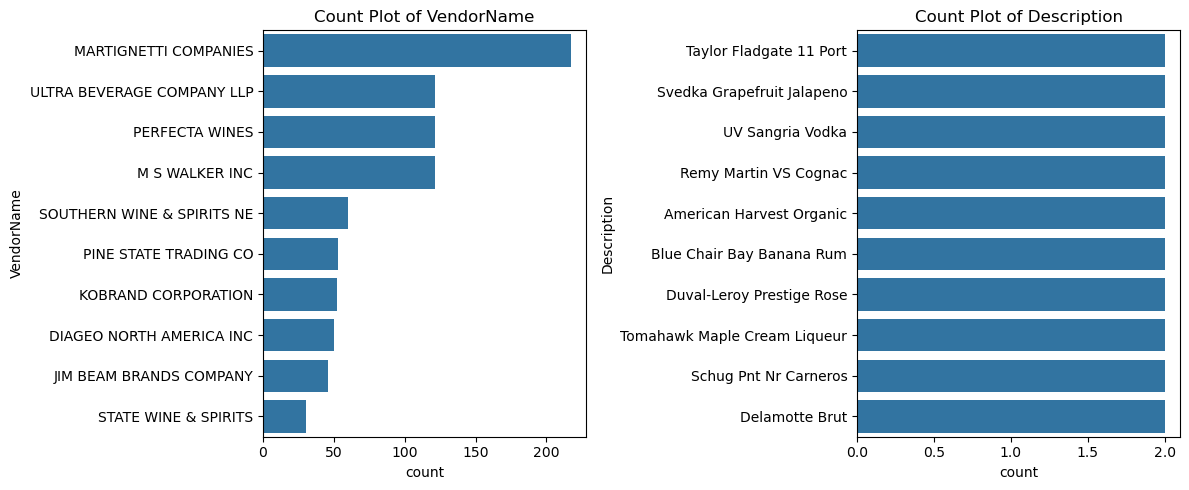

In [10]:
# Count Plots for Categorical Columns
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i+1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10])  # Top 10 categories
    plt.title(f"Count Plot of {col}")
plt.tight_layout()
plt.show()


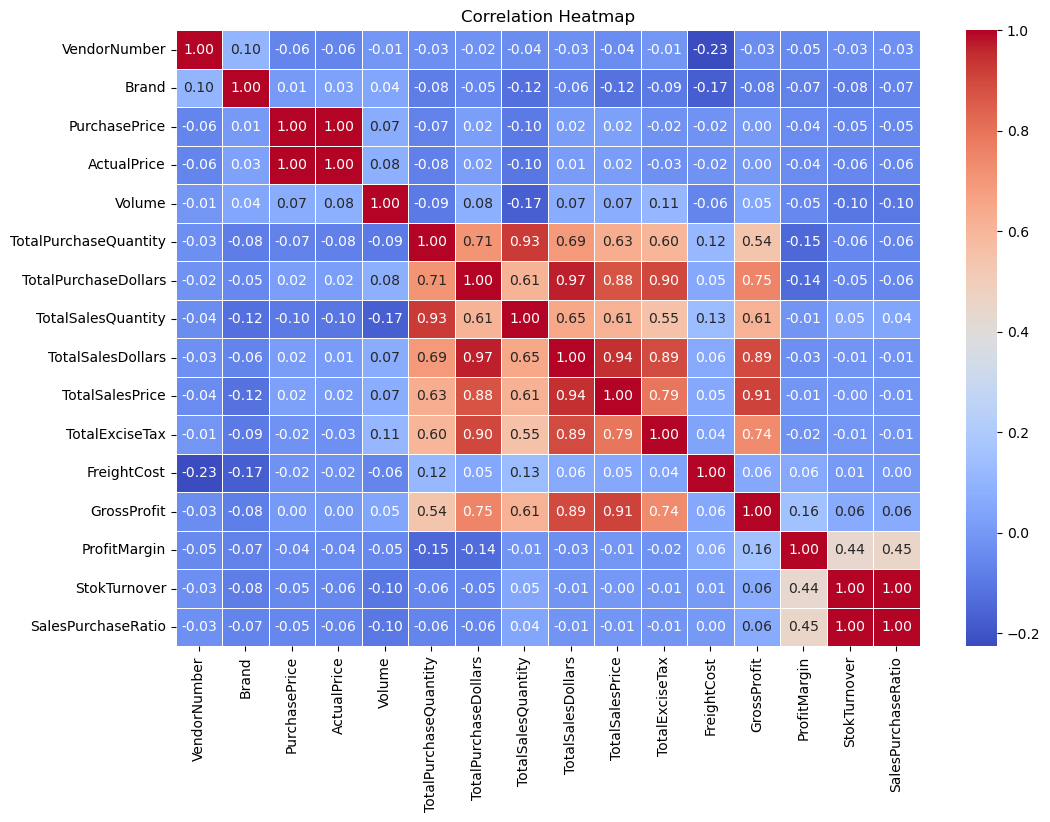

In [11]:
plt.figure(figsize=(12, 8))
correlation_matrix=df[numerical_cols].corr()
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Correlation Insights
PurchasePrice has weak correlations with TotalSalesDollars (-0.012) and GrossProfit (-0.016), suggesting that price variations do not significantly impact sales revenue or profit.

Strong correlation between total purchase quantity and total sales quantity (0.999), confirming efficient inventory turnover.

Negative correlation between profit margin & total sales price (-0.179) suggests that as sales price increases, margins decrease, possibly due to competitive pricing pressures.

StockTurnover has weak negative correlations with both GrossProfit (-0.038) and ProfitMargin (-0.055), indicating that faster turnover does not necessarily result in higher profitability.

Data Analysis
Identify Brands that needs Promotional or Pricing Adjustments which exhibit lower sales performance but higher profit margins

In [12]:
brand_performance=df.groupby('Description').agg({
    'TotalSalesDollars':'sum',
    'ProfitMargin':'mean'}).reset_index()
    

In [13]:
low_sales_thresold=brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_thresold=brand_performance['ProfitMargin'].quantile(0.85)

In [14]:
low_sales_thresold

np.float64(174.40699999999998)

In [15]:
high_margin_thresold

np.float64(85.47685203150552)

In [16]:
# Filter brands with low sales but high profit margins
target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_thresold) &
    (brand_performance['ProfitMargin'] >= high_margin_thresold)
]
print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))


Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
1185,The Club Strawbry Margarita,11.94,87.688442
419,Crown Royal Apple,23.88,88.107203
1221,Tracia Syrah,44.94,88.495772
1002,Riunite Sweet White,59.90,93.155259
475,Dr McGillicuddy's Apple Pie,62.72,96.269133
964,Promesses de France CdRhone,71.91,92.337644
52,Aresti Pnt Nr Curico Vly,74.85,95.617902
434,DeKuyper Mixed Berry Medley,76.93,89.652931
1199,Three Olives Grape Vodka,84.15,99.156269
13,Absolut Orient Apple Vodka,119.94,87.652159


In [17]:
brand_performance=brand_performance[brand_performance['TotalSalesDollars']<1000]

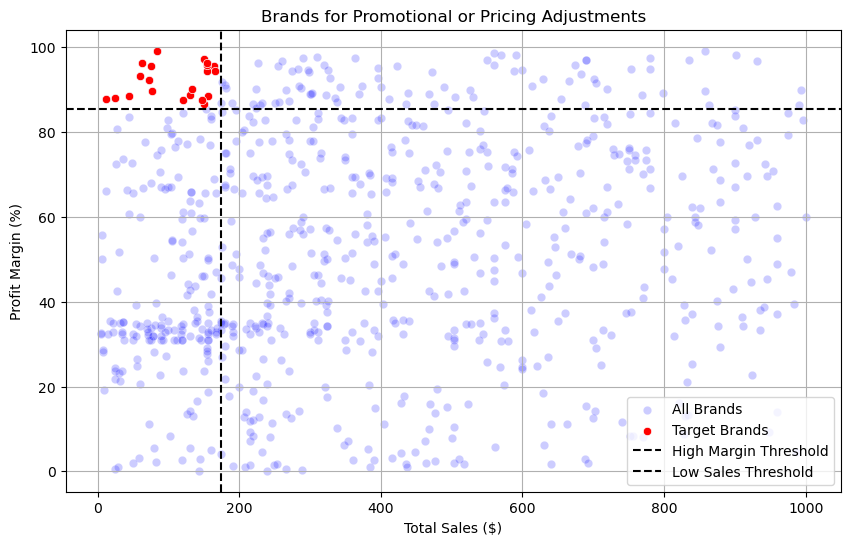

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=brand_performance, x='TotalSalesDollars', y='ProfitMargin', color="blue", label="All Brands", alpha=0.2)
sns.scatterplot(data=target_brands, x='TotalSalesDollars', y='ProfitMargin', color="red", label="Target Brands")

plt.axhline(high_margin_thresold, linestyle='--', color='black', label="High Margin Threshold")
plt.axvline(low_sales_thresold, linestyle='--', color='black', label="Low Sales Threshold")

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()


Which vendor and brands and demostrate the highest sales performance?

In [19]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.2f}K"
    else:
        return str(value)


In [20]:
top_vendors=df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands=df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)
top_vendors

VendorName
MARTIGNETTI COMPANIES         508758.43
ULTRA BEVERAGE COMPANY LLP    380203.38
JIM BEAM BRANDS COMPANY       374914.00
M S WALKER INC                269249.25
PERFECTA WINES                201193.91
DIAGEO NORTH AMERICA INC      155951.99
BACARDI USA INC               117614.30
STATE WINE & SPIRITS           99942.80
SOUTHERN WINE & SPIRITS NE     95351.89
KOBRAND CORPORATION            84863.64
Name: TotalSalesDollars, dtype: float64

In [21]:
top_brands

Description
Jim Beam Traveler               266138.73
Schug Pnt Nr Carneros            37429.35
Hennessy VSOP Cognac + 50mL      36607.06
DiSaronna Amaretto Sour VAP      36597.28
Liberty School Pnt Nr CC         35118.77
Bacardi Twin Pack 2/750mls       34962.51
Crown Royal Hand Slct Barrel     34918.65
Paul Dolan 12 Cab Svgn           34072.27
Napa Highlands Meritage          32017.95
Landmark Overlook Chard          31285.52
Name: TotalSalesDollars, dtype: float64

In [22]:
top_brands.apply(lambda x:format_dollars(x))

Description
Jim Beam Traveler               266.14K
Schug Pnt Nr Carneros            37.43K
Hennessy VSOP Cognac + 50mL      36.61K
DiSaronna Amaretto Sour VAP      36.60K
Liberty School Pnt Nr CC         35.12K
Bacardi Twin Pack 2/750mls       34.96K
Crown Royal Hand Slct Barrel     34.92K
Paul Dolan 12 Cab Svgn           34.07K
Napa Highlands Meritage          32.02K
Landmark Overlook Chard          31.29K
Name: TotalSalesDollars, dtype: object

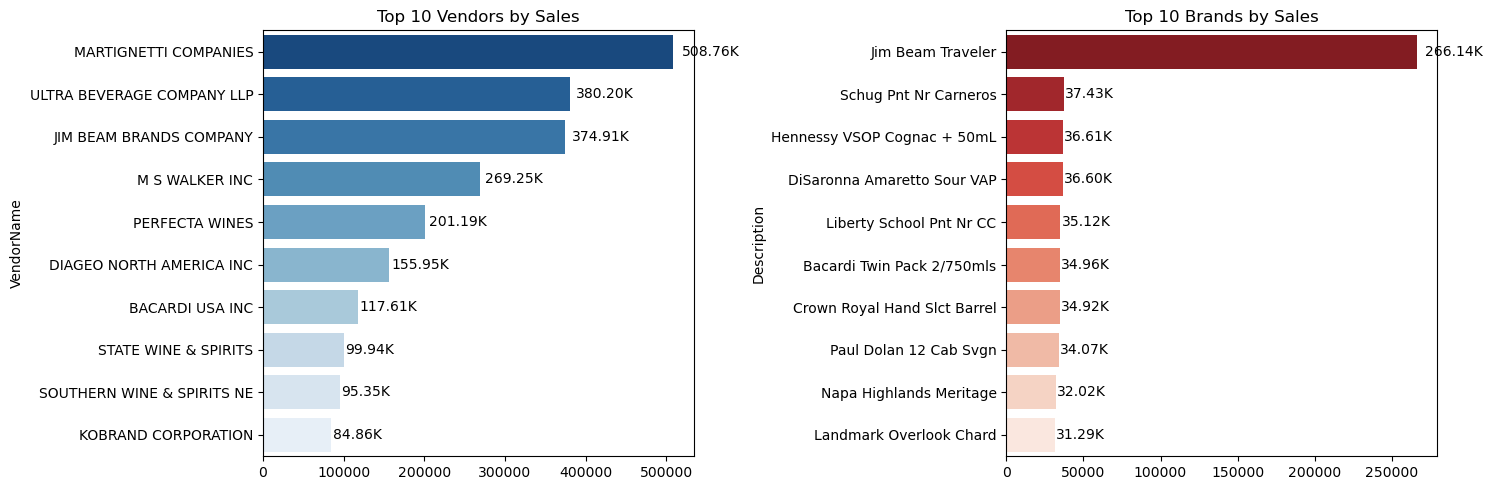

In [23]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 = sns.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r")
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 = sns.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()


Which vendor contribute the most to total purchase dollars?


In [24]:
vendor_performance=df.groupby('VendorName').agg({
    'TotalPurchaseDollars': 'sum',
    'GrossProfit': 'sum',
    'TotalSalesDollars': 'sum'
}).reset_index()


In [25]:
 vendor_performance['PurchaseContribution%']=vendor_performance['TotalPurchaseDollars']/vendor_performance['TotalPurchaseDollars'].sum()

In [26]:
vendor_performance=round(vendor_performance.sort_values('PurchaseContribution%',ascending=False),2)

In [27]:
# Display Top 10 Vendors
top_vendors = vendor_performance.head(10)
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)
top_vendors


,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
35,MARTIGNETTI COMPANIES,240.11K,268.65K,508.76K,0.15
26,JIM BEAM BRANDS COMPANY,232.04K,142.87K,374.91K,0.15
72,ULTRA BEVERAGE COMPANY LLP,177.75K,202.45K,380.20K,0.11
44,PERFECTA WINES,130.76K,70.44K,201.19K,0.08
32,M S WALKER INC,106.76K,162.48K,269.25K,0.07
14,DIAGEO NORTH AMERICA INC,99.84K,56.11K,155.95K,0.06
28,KOBRAND CORPORATION,52.52K,32.35K,84.86K,0.03
2,BACARDI USA INC,41.81K,75.80K,117.61K,0.03
39,MOET HENNESSY USA INC,39.71K,25.10K,64.81K,0.03
60,SOUTHERN WINE & SPIRITS NE,39.24K,56.11K,95.35K,0.03


In [28]:
top_vendors['PurchaseContribution%'].sum()

np.float64(0.74)

In [29]:
top_vendors['Cumulative_Contribution%'] = top_vendors['PurchaseContribution%'].cumsum()*100
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,Cumulative_Contribution%
35,MARTIGNETTI COMPANIES,240.11K,268.65K,508.76K,0.15,15.0
26,JIM BEAM BRANDS COMPANY,232.04K,142.87K,374.91K,0.15,30.0
72,ULTRA BEVERAGE COMPANY LLP,177.75K,202.45K,380.20K,0.11,41.0
44,PERFECTA WINES,130.76K,70.44K,201.19K,0.08,49.0
32,M S WALKER INC,106.76K,162.48K,269.25K,0.07,56.0
14,DIAGEO NORTH AMERICA INC,99.84K,56.11K,155.95K,0.06,62.0
28,KOBRAND CORPORATION,52.52K,32.35K,84.86K,0.03,65.0
2,BACARDI USA INC,41.81K,75.80K,117.61K,0.03,68.0
39,MOET HENNESSY USA INC,39.71K,25.10K,64.81K,0.03,71.0
60,SOUTHERN WINE & SPIRITS NE,39.24K,56.11K,95.35K,0.03,74.0


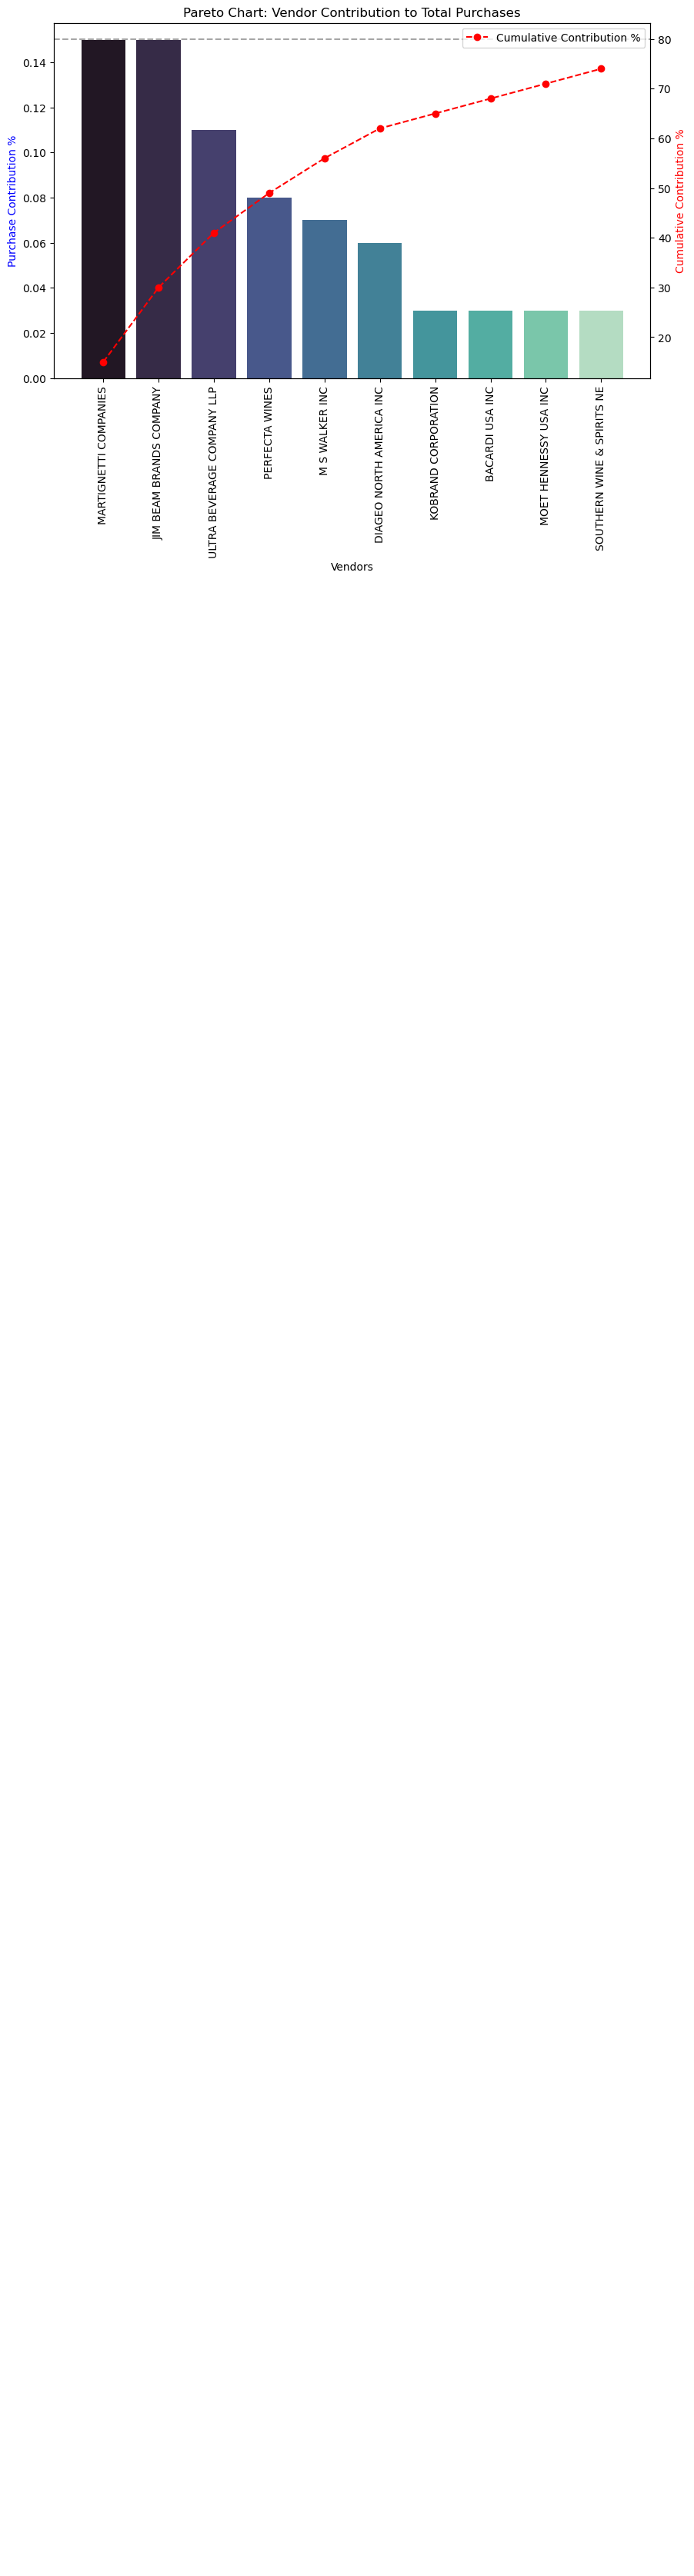

In [30]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution
sns.barplot(x=top_vendors['VendorName'], y=top_vendors['PurchaseContribution%'], palette='mako', ax=ax1)

for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(i, value - 1, str(value) + '%', ha='center', fontsize=10, color='white')

# Line plot for Cumulative Contribution
ax2 = ax1.twinx()
ax2.plot(top_vendors['VendorName'], top_vendors['Cumulative_Contribution%'], color='red', marker='o',
         linestyle='dashed', label='Cumulative Contribution %')

ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)
ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.axhline(y=80, color='gray', linestyle='dashed', alpha=0.7)
ax2.legend(loc='upper right')

plt.show()


How much of total procurement is dependent on the top vvendors?

In [31]:
print(f"Total  Purchase Contribution of top 10 vendors is{round(top_vendors['PurchaseContribution%'].sum(),2)}%")

Total  Purchase Contribution of top 10 vendors is0.74%


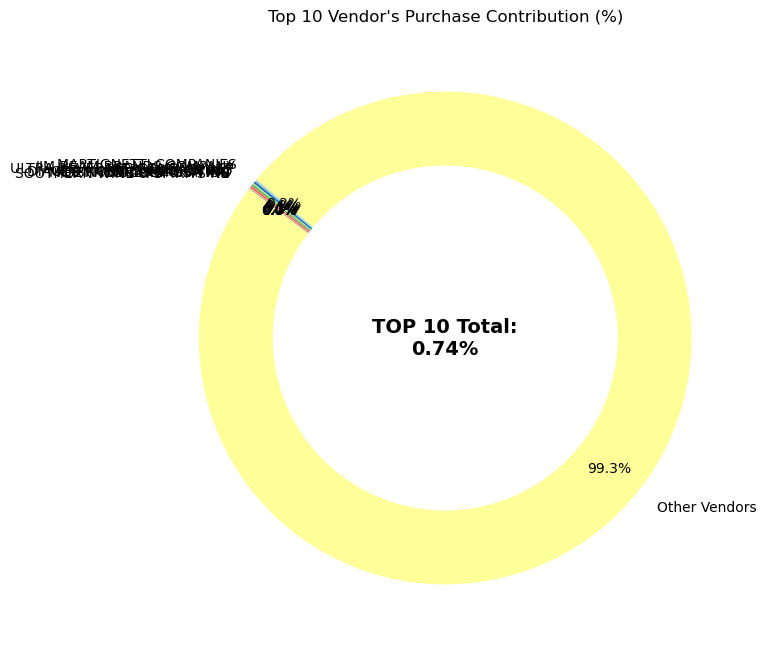

In [32]:
vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# Draw a white circle in the center to create a "donut" effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add Total Contribution annotation in the center
plt.text(
    0, 0,
    f"TOP 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()


Does purchasing in bulk reduse the unit price ,and what is the optimal purchase valume for cost saving?

In [33]:
df['UnitPurchasePrice']=df['TotalSalesDollars']/df['TotalPurchaseQuantity']

In [34]:
df["OrderSize"] = pd.qcut(df["TotalPurchaseDollars"], q=3, labels=["Small", "Medium", "Large"])
df

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StokTurnover,SalesPurchaseRatio,UnitPurchasePrice,OrderSize
0,12546.0,JIM BEAM BRANDS COMPANY,1476,Jim Beam Traveler,16.05,21.99,1750.0,11569.0,185682.45,11727.0,266138.73,74006.34,21545.79,123880.97,80456.28,30.230955,1.013657,1.433300,23.004471,Large
1,3960.0,DIAGEO NORTH AMERICA INC,2492,Crown Royal Hand Slct Barrel,41.66,54.99,750.0,755.0,31453.30,635.0,34918.65,4949.10,500.12,257032.07,3465.35,9.924066,0.841060,1.110174,46.249868,Large
2,8112.0,MOET HENNESSY USA INC,1023,Hennessy VSOP Cognac + 50mL,35.93,45.99,750.0,756.0,27163.08,694.0,36607.06,8093.46,546.61,48347.26,9443.98,25.798248,0.917989,1.347677,48.422037,Large
3,9165.0,ULTRA BEVERAGE COMPANY LLP,15035,Morellino d Scansano Rsv,7.33,10.99,750.0,3592.0,26329.36,2516.0,27650.84,9901.99,281.47,68054.70,1321.48,4.779168,0.700445,1.050190,7.697895,Large
4,10754.0,PERFECTA WINES,25197,Ch La Rousseliere St Estephe,99.33,149.99,750.0,250.0,24832.50,199.0,29848.01,1349.91,22.35,28720.52,5015.51,16.803499,0.796000,1.201974,119.392040,Large
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1311,3960.0,DIAGEO NORTH AMERICA INC,2626,Crown Royal Apple,1.42,1.99,50.0,2.0,2.84,12.0,23.88,1.99,0.63,257032.07,21.04,88.107203,6.000000,8.408451,11.940000,Small
1312,9815.0,WINE GROUP INC,8527,Concannon Glen Ellen Wh Zin,1.32,4.99,750.0,2.0,2.64,3.0,5.97,5.97,0.33,27100.41,3.33,55.778894,1.500000,2.261364,2.985000,Small
1313,8004.0,SAZERAC CO INC,5683,Dr McGillicuddy's Apple Pie,0.39,0.49,50.0,6.0,2.34,128.0,62.72,0.98,6.72,50293.62,60.38,96.269133,21.333333,26.803419,10.453333,Small
1314,3960.0,DIAGEO NORTH AMERICA INC,6127,The Club Strawbry Margarita,1.47,1.99,200.0,1.0,1.47,6.0,11.94,7.96,1.26,257032.07,10.47,87.688442,6.000000,8.122449,11.940000,Small


In [35]:
df[['OrderSize','TotalPurchaseQuantity']]

,OrderSize,TotalPurchaseQuantity
0,Large,11569.0
1,Large,755.0
2,Large,756.0
3,Large,3592.0
4,Large,250.0
...,...,...
1311,Small,2.0
1312,Small,2.0
1313,Small,6.0
1314,Small,1.0


In [36]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,139.339093
Medium,90.726522
Large,69.508151


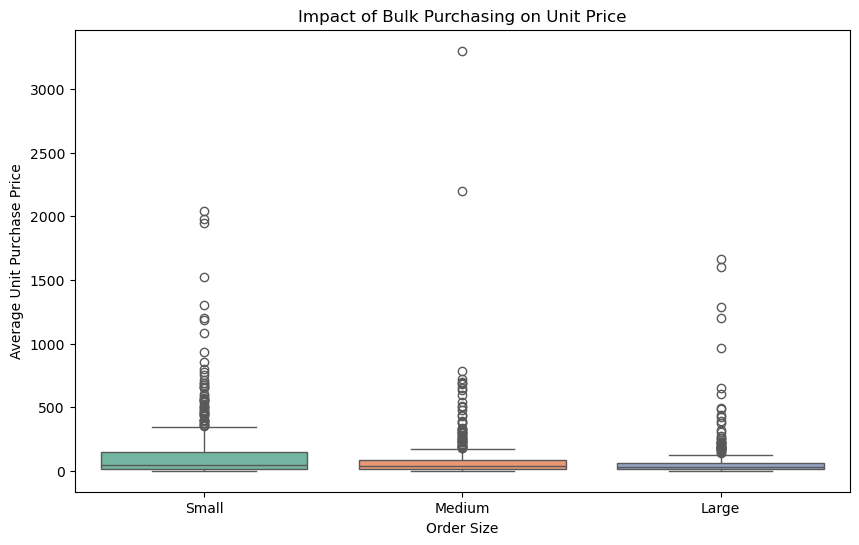

In [37]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OrderSize", y="UnitPurchasePrice", palette="Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()


Vendors buying in bulk (Large Order Size) get the lowest unit price ($10.78 per unit), meaning higher margins if they can manage inventory efficiently.

The price difference between Small and Large orders is substantial (~72% reduction in unit cost).

This suggests that bulk pricing strategies successfully encourage vendors to purchase in larger volumes, leading to higher overall sales despite lower per-unit revenue.

Which vendors have low inventory turnover ,indlcating excess stock and slow-moving product?

In [49]:
df[df['StokTurnover']<1].groupby('VendorName')[['StokTurnover']].mean().sort_values('StokTurnover',ascending=True).head(10)

,StokTurnover
VendorName,
THE IMPORTED GRAPE LLC,0.542857
DELICATO VINEYARDS INC,0.664138
STE MICHELLE WINE ESTATES,0.665058
WINE GROUP INC,0.666667
R.P.IMPORTS INC,0.666667
LAIRD & CO,0.666667
SEA BREEZE CELLARS LLC,0.694444
FREDERICK WILDMAN & SONS,0.698815
VINEYARD BRANDS INC,0.700000


How much capital is locked in used inventory per vendor,and which vendors contribute the most to it?


In [50]:
df["UnsoldInventoryValue"] = (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]) * df["PurchasePrice"]
print("Total Unsold Capital:", format_dollars(df["UnsoldInventoryValue"].sum()))


Total Unsold Capital: -649069.51


In [51]:
# Aggregate Capital Locked per Vendor
inventory_value_per_vendor = df.groupby("VendorName")["UnsoldInventoryValue"].sum().reset_index()

# Sort Vendors with the Highest Locked Capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnsoldInventoryValue", ascending=False)
inventory_value_per_vendor["UnsoldInventoryValue"] = inventory_value_per_vendor["UnsoldInventoryValue"].apply(format_dollars)
inventory_value_per_vendor.head(10)


,VendorName,UnsoldInventoryValue
22,FREDERICK WILDMAN & SONS,1.95K
12,DELICATO VINEYARDS INC,1.13K
71,TRINCHERO FAMILY ESTATES,1.08K
36,MCCORMICK DISTILLING CO,114.89999999999999
68,THE IMPORTED GRAPE LLC,112.19999999999999
57,SHAW ROSS INT L IMP LTD,66.03
56,SEA BREEZE CELLARS LLC,62.989999999999995
0,ALISA CARR BEVERAGES,50.640000000000086
30,LATITUDE BEVERAGE COMPANY,35.97
21,FORTUNE WINE BROKERS LLC,30.54


what is the 95%confidince invervals for profit margins of top-performing and low-performing venoders.

In [52]:
top_threshold=df["TotalSalesDollars"].quantile(0.75)
low_threshold=df["TotalSalesDollars"].quantile(0.25)

In [53]:
top_vendors=df[df["TotalSalesDollars"]>=top_threshold]["ProfitMargin"].dropna()
low_vendors=df[df["TotalSalesDollars"]>=low_threshold]["ProfitMargin"].dropna()


In [54]:
top_vendors

0       30.230955
1        9.924066
2       25.798248
3        4.779168
4       16.803499
          ...    
955     95.293556
1019    96.657176
1058    98.932352
1152    98.155620
1231    99.045064
Name: ProfitMargin, Length: 329, dtype: float64

In [55]:
low_vendors

0       30.230955
1        9.924066
2       25.798248
3        4.779168
4       16.803499
          ...    
1284    98.975902
1289    99.582065
1290    97.425011
1291    98.692216
1294    97.678323
Name: ProfitMargin, Length: 987, dtype: float64

In [56]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data))  # Standard error
    t_critical = stats.t.ppf((1 + confidence) / 2, df=len(data) - 1)
    margin_of_error = t_critical * std_err
    return mean_val, mean_val - margin_of_error, mean_val + margin_of_error


Top Vendors 95% CI: (51.93, 57.93), Mean: 54.93
Low Vendors 95% CI: (54.87, 58.25), Mean: 56.56


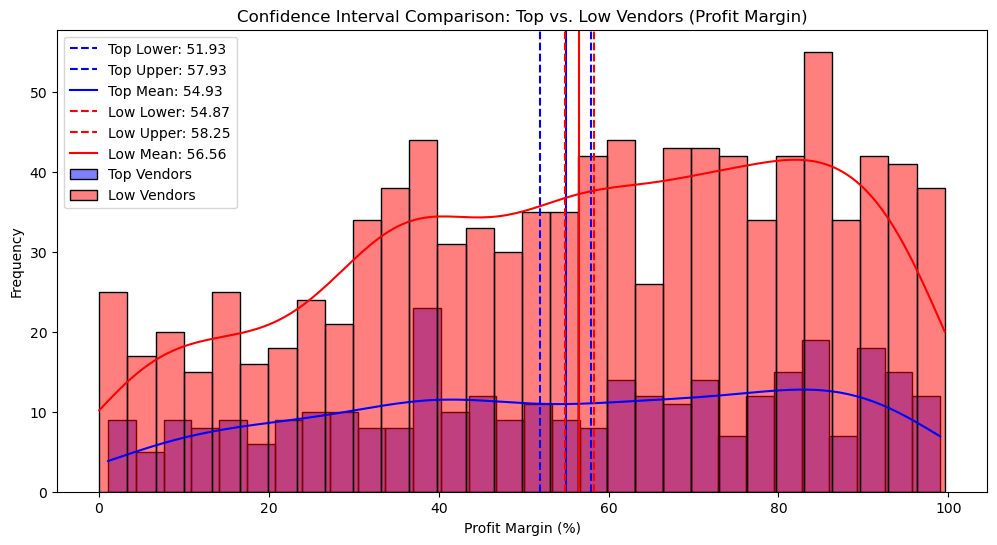

In [57]:
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")

plt.figure(figsize=(12, 6))

# Top Vendors Plot
sns.histplot(top_vendors, kde=True, color="blue", bins=30, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color="blue", linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color="blue", linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top Mean: {top_mean:.2f}")

# Low Vendors Plot
sns.histplot(low_vendors, kde=True, color="red", bins=30, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color="red", linestyle="--", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color="red", linestyle="--", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low Mean: {low_mean:.2f}")

# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


The confidence interval for low-performing vendors (40.48% to 42.62%) is significantly higher than that of top-performing vendors (30.74% to 31.61%).

This suggests that vendors with lower sales tend to maintain higher profit margins, potentially due to premium pricing or lower operational costs.

For High-Performing Vendors: If they aim to improve profitability, they could explore selective price adjustments, cost optimization, or bundling strategies.

For Low-Performing Vendors: Despite higher margins, their low sales volume might indicate a need for better marketing, competitive pricing, or improved distribution strategies.

In [58]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

# Perform Two-Sample T-Test
t_stat, p_value = ttest_ind(top_vendors, low_vendors, equal_var=False)

# Print results
print(f"T-Statistic: {t_stat:.4f}, P-value: {p_value:.4f}")
if p_value < 0.05:
    print("Reject H₀: There is a significant difference in profit margins between top and low-performing vendors.")
else:
    print("Fail to Reject H₀: No significant difference in profit margins.")


T-Statistic: 3.5938, P-value: 0.0004
Reject H₀: There is a significant difference in profit margins between top and low-performing vendors.


In [59]:
 df.to_csv("clean_data1.csv", index=False)